# MASLD Adult K-Means Bootstrap Stability Analysis

This notebook implements only the requested analysis: eight-variable complete-case preprocessing, StandardScaler, Euclidean K-means optimal K selection by silhouette score, final baseline K-means, bootstrap stability using ARI and Jaccard, summaries, plots, and output files.


## 1. Install and Import Packages


In [ ]:
# Run once per new Colab runtime.
!pip install -q numpy pandas scikit-learn scipy matplotlib openpyxl


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.backends.backend_pdf import PdfPages
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
N_BOOTSTRAPS = 1000
K_MIN = 2
K_MAX = 10

DATASET_PATH = "MASLD adult clustering dataset.csv"

OUTPUT_DIR = Path("outputs")
PLOTS_DIR = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

SAVED_FIGURES = []

np.random.seed(RANDOM_STATE)


## 2. Load Dataset and Select Variables


In [ ]:
df = pd.read_csv(DATASET_PATH)

CLUSTERING_VARIABLES = [
    "BMI (kg/m**2)",
    "Waist circumference (cm)",
    "ALT (U/L)",
    "AST (U/L)",
    "Triglycerides (mmol/L)",
    "LDL Friedewald (mmol/L)",
    "Glycohemoglobin (%)",
    "Systolic_BP_avg",
]

EXCLUDED_COLUMNS = [
    "Age",
    "SEQN",
    "Unnamed: 0",
]

missing_columns = [
    column
    for column in CLUSTERING_VARIABLES
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        "Missing required clustering variables: "
        + ", ".join(missing_columns)
    )

selected_data = df[CLUSTERING_VARIABLES].replace("NA", np.nan)

for column in CLUSTERING_VARIABLES:
    selected_data[column] = pd.to_numeric(selected_data[column], errors="coerce")

missing_values = selected_data.isna().sum()
complete_case_data = selected_data.dropna()

if complete_case_data.empty:
    raise ValueError("No complete cases remain after missing-value handling.")

validation_summary = pd.DataFrame(
    {
        "Item": [
            "Original dataset shape",
            "Variables used for clustering",
            "Columns excluded from clustering",
            "Observations before complete-case filtering",
            "Observations after complete-case filtering",
            "Number of clustering variables",
            "Final matrix shape entering K-means",
        ],
        "Value": [
            str(df.shape),
            ", ".join(CLUSTERING_VARIABLES),
            ", ".join(EXCLUDED_COLUMNS),
            len(df),
            len(complete_case_data),
            len(CLUSTERING_VARIABLES),
            str(complete_case_data.shape),
        ],
    }
)

print("Dataset validation summary")
display(validation_summary)

print("Missing values in selected variables")
display(missing_values.to_frame("Missing Values"))

complete_case_data.head()


Dataset validation summary


,Item,Value
0,Original dataset shape,"(1285, 25)"
1,Variables used for clustering,"BMI (kg/m**2), Waist circumference (cm), ALT (..."
2,Columns excluded from clustering,"Age, SEQN, Unnamed: 0"
3,Observations before complete-case filtering,1285
4,Observations after complete-case filtering,1285
5,Number of clustering variables,8
6,Final matrix shape entering K-means,"(1285, 8)"


Missing values in selected variables


,Missing Values
BMI (kg/m**2),0
Waist circumference (cm),0
ALT (U/L),0
AST (U/L),0
Triglycerides (mmol/L),0
LDL Friedewald (mmol/L),0
Glycohemoglobin (%),0
Systolic_BP_avg,0


,BMI (kg/m**2),Waist circumference (cm),ALT (U/L),AST (U/L),Triglycerides (mmol/L),LDL Friedewald (mmol/L),Glycohemoglobin (%),Systolic_BP_avg
0,29.7,120.40,8,14,0.948,2.508,5.6,107.000000
1,26.6,110.65,17,19,1.490,4.241,5.5,139.333333
2,28.1,92.00,19,18,1.152,2.715,8.4,121.333333
3,23.3,87.50,26,31,0.745,1.733,5.6,124.333333
4,46.2,133.80,70,44,2.269,3.077,5.8,161.666667


## 3. Preprocess Data


In [ ]:
# Extract the eight selected variables into a NumPy array.
X = complete_case_data.to_numpy(dtype=np.float64)

# Standardize the feature matrix. This standardized matrix is used for K-means.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = np.asarray(X_scaled, dtype=np.float64)

print("Raw NumPy matrix shape:", X.shape)
print("Standardized NumPy matrix shape:", X_scaled.shape)


Raw NumPy matrix shape: (1285, 8)
Standardized NumPy matrix shape: (1285, 8)


## 4. Find Optimal K Using Silhouette Score


Optimal K-means (K) selection by Silhouette Score


,K,Silhouette Score
0,2,0.161099
1,3,0.184981
2,4,0.189607
3,5,0.174308
4,6,0.161657
5,7,0.138705
6,8,0.135466
7,9,0.128902
8,10,0.133079


Optimal K: 4
Optimal K Silhouette Score: 0.18960699695980804


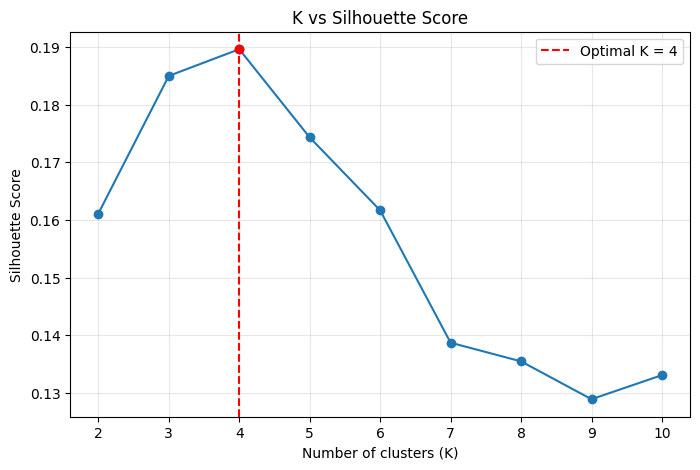

In [ ]:
silhouette_scores = []

for k in range(K_MIN, K_MAX + 1):
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append({"K": k, "Silhouette Score": score})

optimal_k_silhouette_scores = pd.DataFrame(silhouette_scores)

optimal_k = optimal_k_silhouette_scores.loc[
    optimal_k_silhouette_scores["Silhouette Score"].idxmax(), "K"
]
optimal_k_silhouette_score = optimal_k_silhouette_scores[
    "Silhouette Score"
].max()

print("Optimal K-means (K) selection by Silhouette Score")
display(optimal_k_silhouette_scores)
print("Optimal K:", optimal_k)
print("Optimal K Silhouette Score:", optimal_k_silhouette_score)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    optimal_k_silhouette_scores["K"],
    optimal_k_silhouette_scores["Silhouette Score"],
    marker="o",
)
ax.axvline(
    optimal_k,
    color="red",
    linestyle="--",
    label=f"Optimal K = {optimal_k}",
)
ax.scatter(
    [optimal_k],
    [optimal_k_silhouette_score],
    color="red",
    zorder=5,
)
ax.set_title("K vs Silhouette Score")
ax.set_xlabel("Number of clusters (K)")
ax.set_ylabel("Silhouette Score")
ax.set_xticks(optimal_k_silhouette_scores["K"])
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

figure_path = PLOTS_DIR / "K_vs_Silhouette_Score.png"
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)
SAVED_FIGURES.append(figure_path)


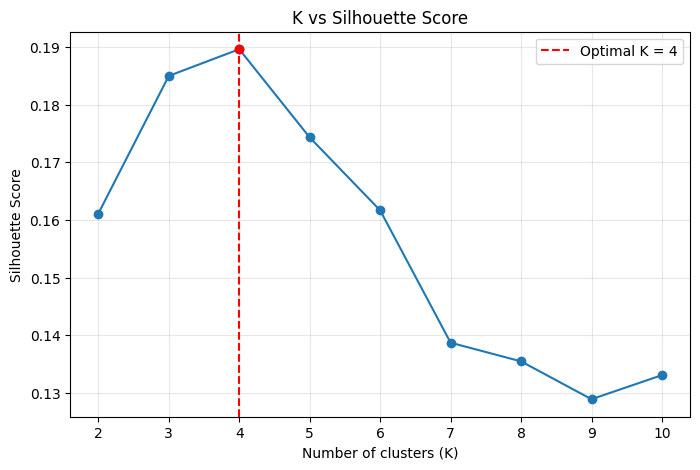

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    optimal_k_silhouette_scores["K"],
    optimal_k_silhouette_scores["Silhouette Score"],
    marker="o",
)
ax.axvline(
    optimal_k,
    color="red",
    linestyle="--",
    label=f"Optimal K = {optimal_k}",
)
ax.scatter(
    [optimal_k],
    [optimal_k_silhouette_score],
    color="red",
    zorder=5,
)
ax.set_title("K vs Silhouette Score")
ax.set_xlabel("Number of clusters (K)")
ax.set_ylabel("Silhouette Score")
ax.set_xticks(optimal_k_silhouette_scores["K"])
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

fig.savefig(
    PLOTS_DIR / "K_vs_Silhouette_Score.png",
    dpi=300,
    bbox_inches="tight",
)


## 5. Final Baseline K-Means


In [ ]:
baseline_kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=RANDOM_STATE,
    n_init=10,
)

baseline_labels = baseline_kmeans.fit_predict(X_scaled)
baseline_labels = np.asarray(baseline_labels, dtype=np.int64)

baseline_cluster_sizes = (
    pd.Series(baseline_labels, name="Cluster")
    .value_counts()
    .sort_index()
    .reset_index()
)
baseline_cluster_sizes.columns = ["Cluster", "Count"]

baseline_silhouette_score = silhouette_score(
    X_scaled,
    baseline_labels,
    metric="euclidean",
)

print("Baseline cluster sizes")
display(baseline_cluster_sizes)

print("Baseline Silhouette Score:", baseline_silhouette_score)


Baseline cluster sizes


,Cluster,Count
0,0,193
1,1,353
2,2,94
3,3,645


Baseline Silhouette Score: 0.18960150085232275


## 6. Bootstrap Stability Functions


In [ ]:
def calculate_cluster_jaccard(
    sampled_indices,
    baseline_labels,
    bootstrap_labels,
    n_clusters,
):
    """Calculate cluster-level and overall Jaccard stability after label matching."""
    sampled_indices = np.asarray(sampled_indices, dtype=np.int64)
    bootstrap_labels = np.asarray(bootstrap_labels, dtype=np.int64)

    unique_sampled_indices = np.unique(sampled_indices)
    jaccard_matrix = np.zeros((n_clusters, n_clusters), dtype=np.float64)

    for baseline_cluster in range(n_clusters):
        baseline_set = set(
            unique_sampled_indices[
                baseline_labels[unique_sampled_indices] == baseline_cluster
            ]
        )

        for bootstrap_cluster in range(n_clusters):
            bootstrap_set = set(
                sampled_indices[bootstrap_labels == bootstrap_cluster]
            )

            union_size = len(baseline_set | bootstrap_set)
            if union_size == 0:
                jaccard = np.nan
            else:
                jaccard = len(baseline_set & bootstrap_set) / union_size

            jaccard_matrix[baseline_cluster, bootstrap_cluster] = jaccard

    # Hungarian assignment minimizes cost, so use negative Jaccard to maximize stability.
    cost_matrix = np.nan_to_num(-jaccard_matrix, nan=0.0)
    baseline_match, bootstrap_match = linear_sum_assignment(cost_matrix)

    matched_jaccards = jaccard_matrix[baseline_match, bootstrap_match]
    overall_jaccard = float(np.nanmean(matched_jaccards))

    cluster_jaccards = {
        f"Cluster {baseline_cluster} Jaccard": float(jaccard_value)
        for baseline_cluster, jaccard_value in zip(
            baseline_match,
            matched_jaccards,
        )
    }

    return overall_jaccard, cluster_jaccards


def summarize_metric(values, metric_name):
    """Summarize one bootstrap stability metric."""
    values = pd.Series(values, dtype="float64").dropna()

    return {
        "Metric": metric_name,
        "Mean": values.mean(),
        "Median": values.median(),
        "Standard Deviation": values.std(),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "2.5th Percentile": values.quantile(0.025),
        "97.5th Percentile": values.quantile(0.975),
    }


## 7. Bootstrap Stability Analysis


In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
n_observations = X_scaled.shape[0]

bootstrap_records = []

print("Number of bootstrap replicates performed:", N_BOOTSTRAPS)

for bootstrap_number in range(1, N_BOOTSTRAPS + 1):
    sampled_indices = rng.choice(
        n_observations,
        size=n_observations,
        replace=True,
    )

    X_bootstrap = X_scaled[sampled_indices]

    bootstrap_kmeans = KMeans(
        n_clusters=optimal_k,
        random_state=RANDOM_STATE + bootstrap_number,
        n_init=10,
    )
    bootstrap_labels = bootstrap_kmeans.fit_predict(X_bootstrap)
    bootstrap_labels = np.asarray(bootstrap_labels, dtype=np.int64)

    bootstrap_silhouette = silhouette_score(
        X_bootstrap,
        bootstrap_labels,
        metric="euclidean",
    )

    baseline_labels_for_sample = baseline_labels[sampled_indices]
    bootstrap_ari = adjusted_rand_score(
        baseline_labels_for_sample,
        bootstrap_labels,
    )

    overall_jaccard, cluster_jaccards = calculate_cluster_jaccard(
        sampled_indices,
        baseline_labels,
        bootstrap_labels,
        optimal_k,
    )

    record = {
        "Bootstrap number": bootstrap_number,
        "Silhouette Score": bootstrap_silhouette,
        "ARI": bootstrap_ari,
        "Overall Jaccard stability": overall_jaccard,
    }
    record.update(cluster_jaccards)
    bootstrap_records.append(record)

bootstrap_results = pd.DataFrame(bootstrap_records)

display(bootstrap_results)


Number of bootstrap replicates performed: 1000


,Bootstrap number,Silhouette Score,ARI,Overall Jaccard stability,Cluster 0 Jaccard,Cluster 1 Jaccard,Cluster 2 Jaccard,Cluster 3 Jaccard
0,1,0.189867,0.780709,0.800498,0.580460,0.894958,0.839286,0.887290
1,2,0.192337,0.722997,0.688233,0.507812,0.847458,0.555556,0.842105
2,3,0.192222,0.850623,0.810189,0.646154,0.881857,0.794521,0.918224
3,4,0.201306,0.823102,0.810652,0.724409,0.872587,0.741379,0.904232
4,5,0.198751,0.911039,0.847562,0.884892,0.934694,0.616667,0.953995
...,...,...,...,...,...,...,...,...
995,996,0.185908,0.784165,0.783429,0.788321,0.837736,0.642857,0.864802
996,997,0.196459,0.955728,0.972946,0.945312,0.972851,1.000000,0.973621
997,998,0.198980,0.820083,0.813684,0.697479,0.899194,0.758065,0.900000
998,999,0.198114,0.828811,0.785679,0.411765,0.920502,0.915254,0.895197


## 8. Bootstrap Stability Summaries


In [ ]:
summary_rows = [
    summarize_metric(bootstrap_results["ARI"], "ARI"),
    summarize_metric(
        bootstrap_results["Overall Jaccard stability"],
        "Overall Jaccard stability",
    ),
    summarize_metric(
        bootstrap_results["Silhouette Score"],
        "Bootstrap Silhouette Score",
    ),
]

bootstrap_stability_summary = pd.DataFrame(summary_rows)

cluster_jaccard_columns = [
    column
    for column in bootstrap_results.columns
    if column.startswith("Cluster ") and column.endswith(" Jaccard")
]

cluster_jaccard_summary = pd.DataFrame(
    [
        summarize_metric(bootstrap_results[column], column)
        for column in cluster_jaccard_columns
    ]
)

print("Bootstrap stability summary")
display(bootstrap_stability_summary)

print("Cluster-specific Jaccard summary")
display(cluster_jaccard_summary)


Bootstrap stability summary


,Metric,Mean,Median,Standard Deviation,Minimum,Maximum,2.5th Percentile,97.5th Percentile
0,ARI,0.842494,0.842152,0.074153,0.556076,0.988419,0.696409,0.966409
1,Overall Jaccard stability,0.840760,0.841291,0.075820,0.622735,0.988025,0.699812,0.972242
2,Bootstrap Silhouette Score,0.192588,0.192341,0.008223,0.167896,0.223602,0.176381,0.209357


Cluster-specific Jaccard summary


,Metric,Mean,Median,Standard Deviation,Minimum,Maximum,2.5th Percentile,97.5th Percentile
0,Cluster 0 Jaccard,0.742362,0.725917,0.145672,0.376289,1.000000,0.479004,0.970417
1,Cluster 1 Jaccard,0.907678,0.909474,0.042928,0.754386,0.995726,0.816647,0.978704
2,Cluster 2 Jaccard,0.800114,0.826761,0.145169,0.323077,1.000000,0.517148,1.000000
3,Cluster 3 Jaccard,0.912888,0.912281,0.040644,0.742529,0.995062,0.831346,0.980449


fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(bootstrap_results["ARI"], bins=30, edgecolor="black")
ax.set_title("Distribution of Bootstrap ARI Values")
ax.set_xlabel("ARI")
ax.set_ylabel("Frequency")
plt.show()

figure_path = PLOTS_DIR / "Bootstrap_ARI_Distribution.png"
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)
SAVED_FIGURES.append(figure_path)


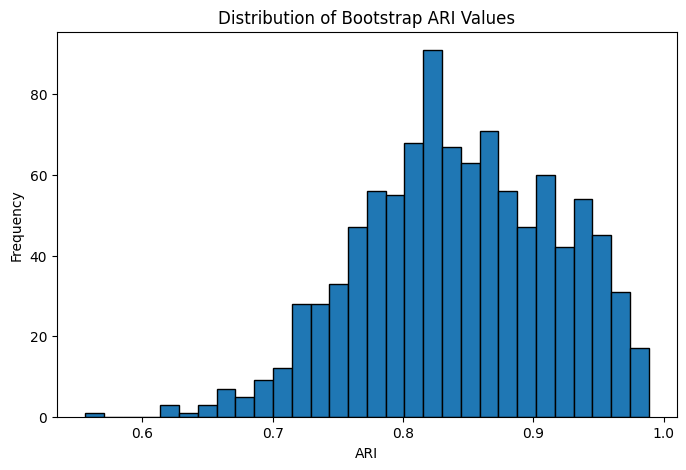

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(bootstrap_results["ARI"], bins=30, edgecolor="black")
ax.set_title("Distribution of Bootstrap ARI Values")
ax.set_xlabel("ARI")
ax.set_ylabel("Frequency")
plt.show()

fig.savefig(
    PLOTS_DIR / "Bootstrap_ARI_Distribution.png",
    dpi=300,
    bbox_inches="tight",
)


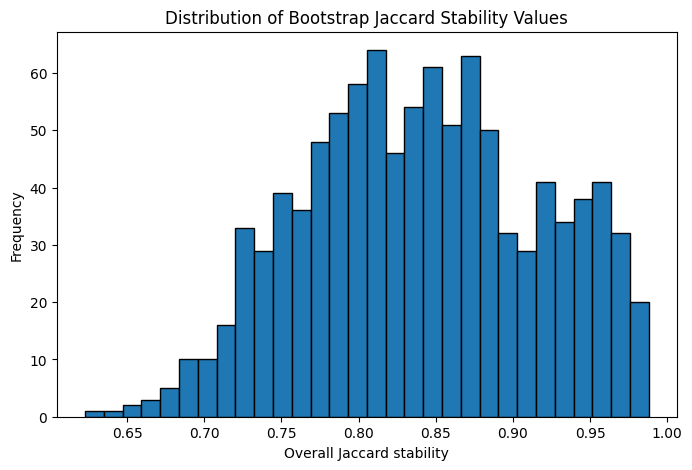

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    bootstrap_results["Overall Jaccard stability"],
    bins=30,
    edgecolor="black",
)
ax.set_title("Distribution of Bootstrap Jaccard Stability Values")
ax.set_xlabel("Overall Jaccard stability")
ax.set_ylabel("Frequency")
plt.show()

figure_path = PLOTS_DIR / "Bootstrap_Jaccard_Distribution.png"
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)
SAVED_FIGURES.append(figure_path)


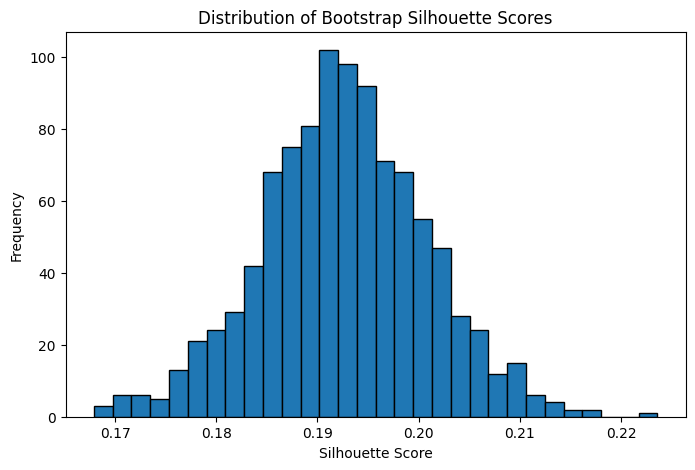

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    bootstrap_results["Silhouette Score"],
    bins=30,
    edgecolor="black",
)
ax.set_title("Distribution of Bootstrap Silhouette Scores")
ax.set_xlabel("Silhouette Score")
ax.set_ylabel("Frequency")
plt.show()

figure_path = PLOTS_DIR / "Bootstrap_Silhouette_Distribution.png"
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)
SAVED_FIGURES.append(figure_path)


/tmp/ipykernel_1320/1343269407.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


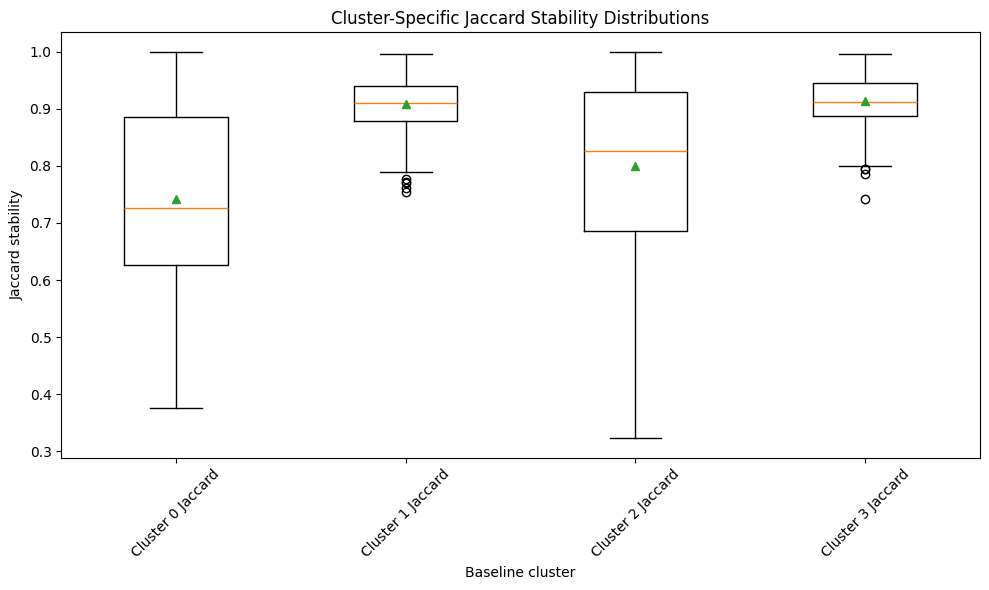

In [ ]:
if cluster_jaccard_columns:
    cluster_jaccard_values = [
        bootstrap_results[column].dropna()
        for column in cluster_jaccard_columns
    ]

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.boxplot(
        cluster_jaccard_values,
        labels=cluster_jaccard_columns,
        showmeans=True,
    )
    ax.set_title("Cluster-Specific Jaccard Stability Distributions")
    ax.set_xlabel("Baseline cluster")
    ax.set_ylabel("Jaccard stability")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

    figure_path = PLOTS_DIR / "Cluster_Specific_Jaccard_Distributions.png"
    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
    )
    SAVED_FIGURES.append(figure_path)


## 10. Export Output Files


In [ ]:
optimal_k_summary = pd.DataFrame(
    [
        {
            "Optimal K": optimal_k,
            "Optimal K Silhouette Score": optimal_k_silhouette_score,
            "Baseline Silhouette Score": baseline_silhouette_score,
            "Bootstrap Replicates": N_BOOTSTRAPS,
            "Observations Used": X_scaled.shape[0],
            "Variables Used": X_scaled.shape[1],
        }
    ]
)

optimal_k_silhouette_scores.to_csv(
    OUTPUT_DIR / "optimal_k_silhouette_scores.csv",
    index=False,
)
bootstrap_results.to_csv(
    OUTPUT_DIR / "bootstrap_results.csv",
    index=False,
)
bootstrap_stability_summary.to_csv(
    OUTPUT_DIR / "bootstrap_stability_summary.csv",
    index=False,
)
cluster_jaccard_summary.to_csv(
    OUTPUT_DIR / "cluster_jaccard_summary.csv",
    index=False,
)
baseline_cluster_sizes.to_csv(
    OUTPUT_DIR / "baseline_cluster_sizes.csv",
    index=False,
)
optimal_k_summary.to_csv(
    OUTPUT_DIR / "optimal_k_summary.csv",
    index=False,
)

excel_report_path = OUTPUT_DIR / "MASLD_adult_kmeans_bootstrap_results.xlsx"

with pd.ExcelWriter(excel_report_path, engine="openpyxl") as writer:
    validation_summary.to_excel(writer, sheet_name="Validation", index=False)
    missing_values.to_frame("Missing Values").to_excel(
        writer,
        sheet_name="Missing Values",
    )
    optimal_k_silhouette_scores.to_excel(
        writer,
        sheet_name="Optimal K",
        index=False,
    )
    optimal_k_summary.to_excel(
        writer,
        sheet_name="Optimal K Summary",
        index=False,
    )
    baseline_cluster_sizes.to_excel(
        writer,
        sheet_name="Baseline Cluster Sizes",
        index=False,
    )
    bootstrap_results.to_excel(
        writer,
        sheet_name="Bootstrap Results",
        index=False,
    )
    bootstrap_stability_summary.to_excel(
        writer,
        sheet_name="Stability Summary",
        index=False,
    )
    cluster_jaccard_summary.to_excel(
        writer,
        sheet_name="Cluster Jaccard",
        index=False,
    )

plots_report_path = OUTPUT_DIR / "Plots_Report.pdf"

with PdfPages(plots_report_path) as pdf:
    for figure in SAVED_FIGURES:
        image = plt.imread(figure)
        height, width = image.shape[:2]
        fig_width = 8.5
        fig_height = max(1, fig_width * height / width)

        fig, ax = plt.subplots(figsize=(fig_width, fig_height))
        ax.imshow(image)
        ax.axis("off")
        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

print("Output files saved in:", OUTPUT_DIR)
print("Plots saved in:", PLOTS_DIR)
print("Excel report saved to:", excel_report_path)
print("All-plots PDF saved to:", plots_report_path)

print("Required CSV files:")
print("- optimal_k_silhouette_scores.csv")
print("- bootstrap_results.csv")
print("- bootstrap_stability_summary.csv")
print("- cluster_jaccard_summary.csv")


Output files saved in: outputs
Plots saved in: outputs/plots
Excel report saved to: outputs/MASLD_adult_kmeans_bootstrap_results.xlsx
All-plots PDF saved to: outputs/Plots_Report.pdf
Required CSV files:
- optimal_k_silhouette_scores.csv
- bootstrap_results.csv
- bootstrap_stability_summary.csv
- cluster_jaccard_summary.csv
